# 01. Forced photometry on Euclid NISP with a VIS prior

This notebook measures VIS and NISP (Y, J, H) fluxes for every MER source in a 200 arcsec
field of the Euclid Deep Field North and assembles them into a catalog with uncertainties, AB
magnitudes, and quality flags. VIS has the sharpest PSF, about 0.2 arcsec FWHM against 0.5 arcsec
in the NISP mosaics, so positions and profiles are fitted on VIS and then held fixed while only
the fluxes are fitted in Y, J, and H. This assumes that a source looks the same in every band,
which color gradients can violate.

[Notebook 00](00_how_tractor_works.ipynb) shows both fits on one galaxy. The sections below go
through each step for a whole field: the MER catalog and the cutouts, the PSF models,
choosing a profile for every source, the VIS fit and its diagnostics, the calibration of the
flux errors, the NISP fits, and the final catalog. The one-call driver of notebook 05 runs the
same steps without the intermediate views.

## 1. Setup and target

A 200 arcsec region of EDF-N with roughly a thousand MER sources.


In [ ]:
DATA_ACCESS = "DR1"  ## Choose "DR1" or "Q1".
import euclid_phot as ep
ep.set_data_access(DATA_ACCESS)

import time

import numpy as np
import matplotlib.pyplot as plt
from astropy.stats import mad_std
from astropy.table import Table


plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.titlesize": 17,
})

TARGET_RA = 269.48
TARGET_DEC = 67.30
CUTOUT_SIZE_ARCSEC = 200.0  ## memory and run time: README, "Computing cost"

DATA_DIR = ep.get_data_dir()  ## download cache; set EUCLID_PHOT_DATA_DIR to move it

## 2. Pipeline overview

The diagram below shows the workflow of this notebook.

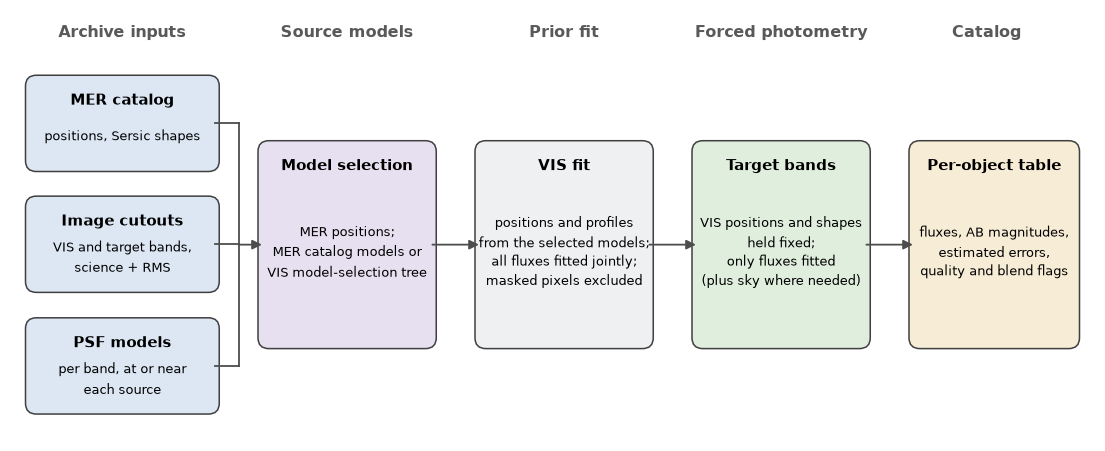

In [3]:
ep.viz.plot_workflow()
plt.show()


*The pipeline, from the archive inputs to the multi-band catalog.*

The fit is configured by the settings below. The source list comes from the MER catalog, and
the models are built on VIS and then carried to the target bands. How each source gets its
profile is set by `model_selection`: with `"prior"` the MER classification and Sérsic shape are
used as they are, and with `"tree"` several profiles are fitted to the VIS pixels and the
simplest one that fits well is kept, as section 6 describes. The two remaining `PRIOR` entries
only apply on the prior path, where the shapes can be re-optimized after the first flux fit and
the positions allowed to shift slightly. Bright stars are masked, and the fits are spread over
parallel workers.


In [4]:
PRIOR = {
    "band": "VIS",
    "objects": "mer",
    "model_selection": "tree",
    "free_shapes": True,    # ignored on the tree path: shapes fit per blob
    "refine_positions": False,
}

MASK_BRIGHT_STARS = True

TARGET_BANDS = {"euclid": ("Y", "J", "H")}

N_WORKERS = 10

## 3. The MER catalog

The MER catalog supplies positions, point-likeness probabilities, and
Sérsic parameters where MER measured them. The query below keeps the rows
with a positive VIS PSF flux, reading a cached copy when one exists and
asking IRSA otherwise.


In [5]:
mer_path = DATA_DIR / "catalogs" / f"mer_catalog_{TARGET_RA:.4f}_{TARGET_DEC:.4f}_{int(CUTOUT_SIZE_ARCSEC)}.fits"
half_size_deg = CUTOUT_SIZE_ARCSEC / 2.0 / 3600.0
mer_cat = ep.query_mer_catalog(TARGET_RA, TARGET_DEC, half_size_deg)
print(f"queried IRSA TAP: {len(mer_cat)} sources")


queried IRSA TAP: 2371 sources


/var/folders/tn/vrvc8r7n4yz1j60w20cdvr2c0000gp/T/ipykernel_28442/2157684451.py:3: UserWarning: DR1 morphology_table is not configured in src/conf.json; Sersic shape columns are masked. The existing source builder uses its isophotal/exponential fallback; tree-selected shapes are still fitted to the VIS pixels.
  mer_cat = ep.query_mer_catalog(TARGET_RA, TARGET_DEC, half_size_deg)


## 4. Fetching the Euclid cutouts

`fetch_cutout` copies the requested pixels out of one MER tile, keeping
the tile's own pixel grid, and takes the science, RMS and flag planes
from the same tile as the PSFs. The cutouts are cached locally. A field
that extends beyond one tile has to be fitted tile by tile.

All four MER mosaics are delivered on 0.1 arcsec pixels; what differs
between them is the PSF, about 0.2 arcsec FWHM in VIS and 0.5 arcsec in
NISP. The NISP detectors have 0.3 arcsec pixels, which MER resamples onto the VIS
grid, and the fits use those resampled pixels.

In [6]:
cutouts = {}
for band in ('VIS', 'Y', 'J', 'H'):
    cutouts[band] = ep.fetch_cutout(
        band, TARGET_RA, TARGET_DEC, CUTOUT_SIZE_ARCSEC,
        with_flag=True, force_download=True)

for band, c in cutouts.items():
    print(f"  {band}: shape={c.shape}, pixel scale={c.pixel_scale_arcsec:.3f} arcsec/pix")

# A boundary source is clipped by the cutout (the `edge` flag of section 10),
# but its light must stay in the model or a neighbour absorbs it.
mer_cat = ep.trim_catalog_to_cutout(
    mer_cat, cutouts['VIS'].wcs, cutouts['VIS'].shape)
print(f"\non the image: {len(mer_cat)} sources")


  VIS: shape=(2000, 2000), pixel scale=0.100 arcsec/pix
  Y: shape=(2000, 2000), pixel scale=0.100 arcsec/pix
  J: shape=(2000, 2000), pixel scale=0.100 arcsec/pix
  H: shape=(2000, 2000), pixel scale=0.100 arcsec/pix

on the image: 2365 sources


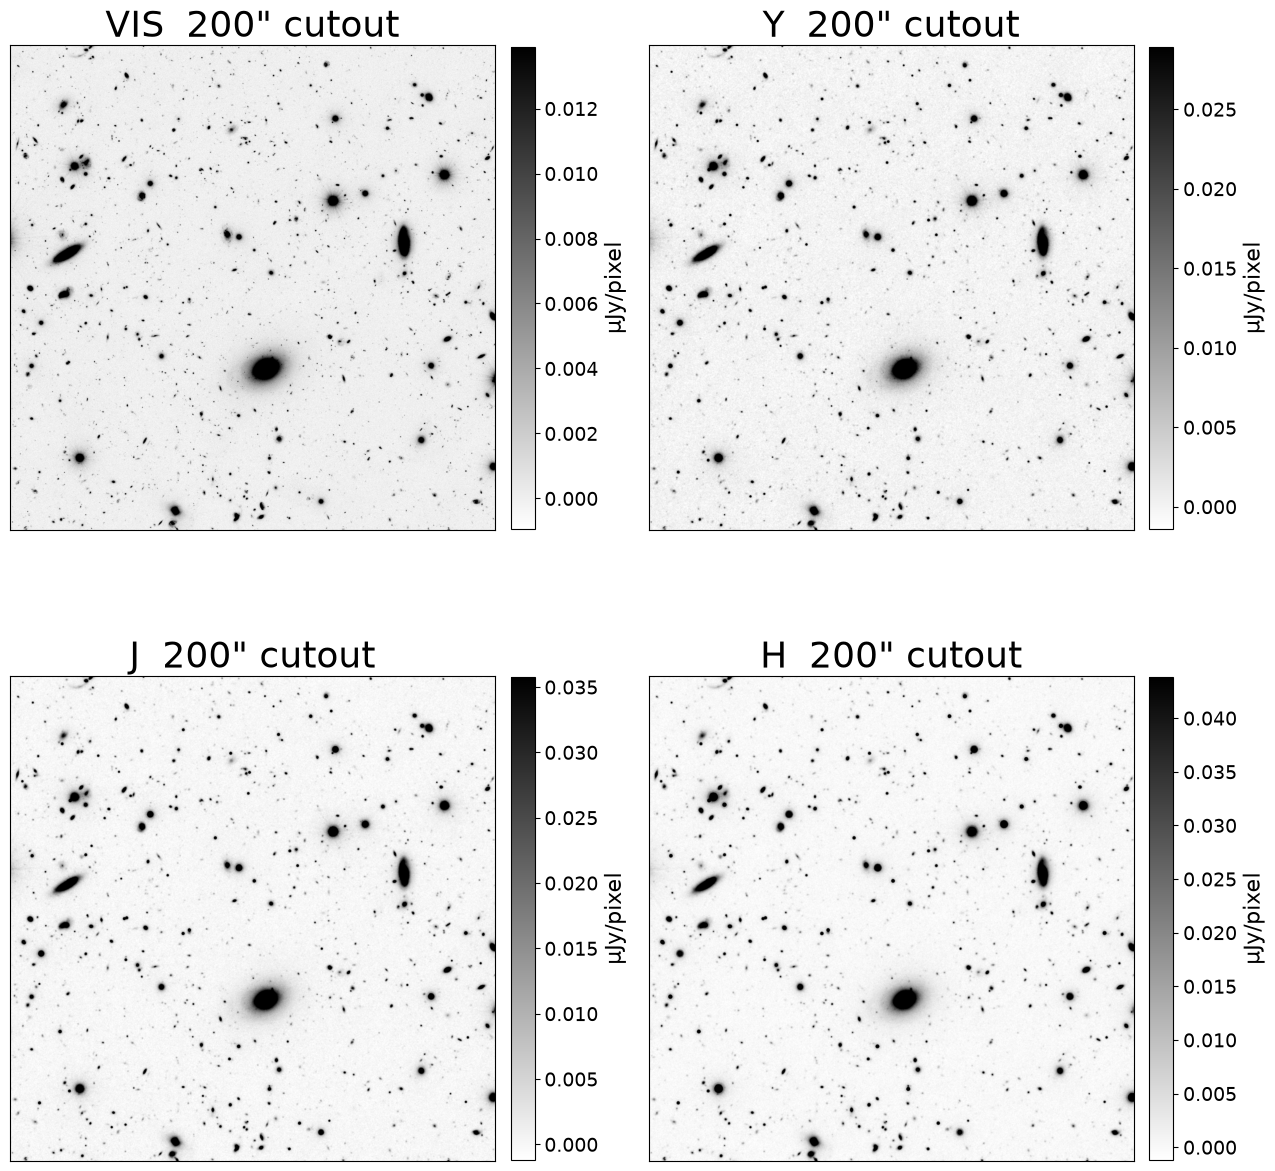

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for ax, band in zip(axes.ravel(), ('VIS', 'Y', 'J', 'H')):
    ep.viz.show_cutout(cutouts[band], ax=ax,
                       title=f"{band}  {CUTOUT_SIZE_ARCSEC:.0f}\" cutout")
    ax.title.set_fontsize(26)
plt.tight_layout(); plt.show()


*The same 200 arcsec field in VIS, Y, J, and H, on the common 0.1 arcsec grid.*

## 5. The VIS PSF and the Tractor image

Euclid provides its PSF model in two products: GRID-PSF samples it on a
regular grid, CATALOG-PSF at the MER catalogue positions. This notebook
uses GRID in all Euclid bands, and each source is rendered with its
nearest sample while overlapping sources are still fitted together. To
compare the two products, change `PSF_PRODUCT` below and restart the
notebook.

The Tractor image bundles the cutout pixels, their inverse variance, the PSF, and the mask of
pixels to leave out of the fit, as notebook 00 showed for a single source.

In [8]:
PSF_PRODUCT = "grid"  # "catalog" is also supported
extract_psf = {"grid": ep.extract_grid_psf, "catalog": ep.extract_catalog_psf}[PSF_PRODUCT]

psf_data_vis = extract_psf(
    "VIS", TARGET_RA, TARGET_DEC, radius_arcsec=150.0,
    tile_id=cutouts["VIS"].header.get("MERTILE"), force_download=True)
psf_fwhm_vis = float(np.median(psf_data_vis["fwhm"]))
print(f"VIS {PSF_PRODUCT.upper()}-PSF: {len(psf_data_vis['stamps'])} stamps, "
      f"median FWHM = {psf_fwhm_vis:.3f} arcsec")

# Halos and diffraction spikes are real light the PSF stamp cannot model;
# the MER STARSIGNAL bit vetoes those pixels.
star_mask = ep.starsignal_pixel_mask(cutouts['VIS']) if MASK_BRIGHT_STARS else None
if star_mask is not None:
    print(f"STARSIGNAL bright-star mask: {int(star_mask.sum())} pixels "
          f"({100*star_mask.mean():.2f}%) excluded from the fit")

tim_vis = ep.build_tractor_image(
    cutouts['VIS'], psf_data=psf_data_vis, pixel_mask=star_mask)
_flg = cutouts['VIS'].flag
if _flg is not None:
    _nbad = int(((_flg & ep.MER_VIS_BAD_BITS) != 0).sum())
    print(f"VIS FLG plane attached; {_nbad} pixel(s) carry coadd-fatal bits "
          f"(INVALID/SAT/NO_DATA) and are excluded from the fit.")


VIS GRID-PSF: 493 stamps, median FWHM = 0.203 arcsec
STARSIGNAL bright-star mask: 206294 pixels (5.16%) excluded from the fit
VIS FLG plane attached; 25450 pixel(s) carry coadd-fatal bits (INVALID/SAT/NO_DATA) and are excluded from the fit.


### Spatial coverage of the selected PSF samples

The plot shows the sample positions, their FWHM, and the coverage of the
cutout. Nearest-sample selection does not interpolate between stamps, so
the local variation matters for extended sources.

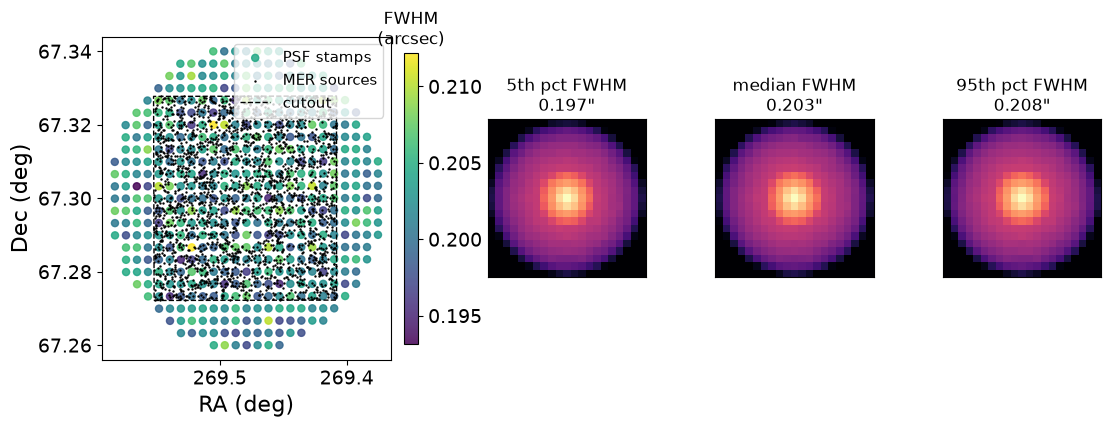

493 PSF samples, median spacing 12.0 arcsec
FWHM across the field: 0.193-0.212 arcsec (median 0.203)


In [9]:
fig, info = ep.viz.show_psf_grid(psf_data_vis, cutout=cutouts['VIS'],
                                 mer_cat=mer_cat)
plt.show()
print(f"{info['n_stamps']} PSF samples, median spacing "
      f"{info['median_spacing_arcsec']:.1f} arcsec")
print(f"FWHM across the field: {info['fwhm_min']:.3f}-"
      f"{info['fwhm_max']:.3f} arcsec (median {info['fwhm_median']:.3f})")


*Left: the selected VIS PSF samples over the cutout footprint, coloured by FWHM. Right: the
stamps at the 5th percentile, median, and 95th percentile FWHM, on a log stretch.*

## 6. The source list

Every MER source gets a model, and the configuration decides how. With the prior option a
source is a point source when its MER point-likeness is above 0.96 or its effective radius is
below half the VIS PSF FWHM; otherwise it takes the MER Sérsic shape, falling back to an
exponential where MER measured none.

With the tree, the default here, the VIS image is first segmented into blobs, connected
regions of significant pixels found with SEP, the Python port of SExtractor, and the sources
in each blob are fitted together. For every source the tree compares a point source, a fixed
circular exponential, an exponential, a de Vaucouleurs, and a composite profile by reduced
chi-squared, stopping as soon as a point source is sufficient. Resolved sources in a blob with
S/N of at least 20 also try a free-index Sérsic profile, kept when the total chi-squared
improves by more than 25. The tree also refines the VIS positions, accepting shifts of up to
0.3 arcsec. The procedure adapts [The Farmer](https://arxiv.org/abs/2310.07757), and
[the model-selection notebook](supporting_notebooks/model_selection.ipynb) traces it on one
blob. A source outside every blob keeps its MER prior, so every input row has a model and the
output stays in the order of the input catalog.

Why refit models MER already provides: the MER shapes come from MER's own fitting, with its own
PSF model and treatment of neighbours, while here every model is rendered by The Tractor and
fitted together with its neighbours. The model-selection notebook compares the two on a 50 arcsec
field: the tree describes the VIS pixels of the few bright galaxies clearly better, and makes no
difference for faint sources. The tree dominates the run time and memory of this notebook (README,
"Computing cost"). Setting `"model_selection": "prior"` in `PRIOR` skips it and uses the MER
models, which is adequate for faint, isolated sources.

In [10]:
t0 = time.time()
if PRIOR["model_selection"] == "tree":
    print("Running the chi-squared decision tree on the prior image...")
    # Compare profile classes jointly with their neighbours on VIS.
    sources_list, _ = ep.run_model_selection(
        mer_cat, tim_vis,
        cutouts[PRIOR["band"]].data, tim_vis.getInvvar(),
        pixscale_arcsec=cutouts[PRIOR["band"]].pixel_scale_arcsec,
        n_workers=N_WORKERS,
    )
    # Rows the tree could not place fall back to their MER prior.
    fallback = ep.build_sources_from_mer(
        mer_cat, band=PRIOR["band"], psf_fwhm_arcsec=psf_fwhm_vis)
    sources = [s if s is not None else fb
               for s, fb in zip(sources_list, fallback)]
else:  # model_selection == "prior"
    print("Using the MER Sérsic catalog priors.")
    sources = ep.build_sources_from_mer(
        mer_cat, band=PRIOR["band"], psf_fwhm_arcsec=psf_fwhm_vis)

class_hist = {}
for s in sources:
    class_hist[type(s).__name__] = class_hist.get(type(s).__name__, 0) + 1
print(f"\nbuilt {len(sources)} sources in {time.time()-t0:.1f} s")
for k in sorted(class_hist):
    print(f"  {k:<22s} {class_hist[k]}")


Running the chi-squared decision tree on the prior image...

built 2365 sources in 449.8 s
  DevGalaxy              247
  ExpGalaxy              1165
  FixedCompositeGalaxy   200
  PointSource            485
  SersicGalaxy           233
  SimpleGalaxy           35


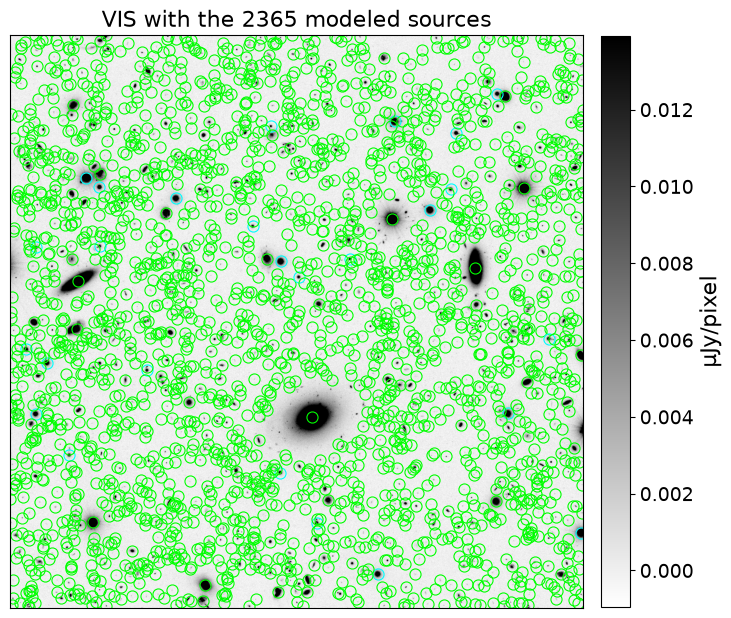

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
ep.viz.show_cutout(cutouts['VIS'], mer_cat, ax=ax,
                   title=f"VIS with the {len(sources)} modeled sources")
plt.show()


*The modeled source list over the VIS prior image: cyan circles are
stars, green circles galaxies, following the MER classifier.*


## 7. Flux-only forced photometry

Freeze positions and shapes, then fit all the fluxes together. A coarse
guard, `fit_quality`, drops a source whose VIS flux comes out negative or
more than 100 times its MER `flux_vis_sersic`; it catches fits that ran
away, not fits that are merely poor.

In [12]:
initial_vis_ujy = np.asarray(mer_cat['flux_vis_sersic'], dtype=float)
tractor_vis, fit_quality, vis_err_ujy = ep.fit_forced_photometry(
    tim_vis, sources, band='VIS',
    initial_fluxes_ujy=initial_vis_ujy, return_errors=True,
)
print(f"VIS flux guard passed: {int(fit_quality.sum())}/{len(sources)} sources.")
print(f"median formal 1-sigma flux error (flux-only fit): "
      f"{np.nanmedian(vis_err_ujy[fit_quality]):.3f} microJansky")


VIS flux guard passed: 2355/2365 sources.
median formal 1-sigma flux error (flux-only fit): 0.005 microJansky


## 8. Free shapes for interior galaxies

On the tree path, which this notebook uses, this step is skipped: the tree has already fitted
the shapes of every source in each blob with the bounded optimizer, and they stay frozen from
here on. On the prior path, galaxies more than 50 pixels from the cutout edges have their shape
parameters, including the Sérsic index, re-optimized jointly with brightness while positions
stay fixed, unless `free_shapes` is off.

In [13]:
if PRIOR["free_shapes"] and PRIOR["model_selection"] != "tree":
    fit_quality, n_thawed = ep.fit_free_shapes(
        tractor_vis, tim_vis, sources, fit_quality,
        band=PRIOR["band"], initial_fluxes_ujy=initial_vis_ujy,
    )
    print(f"Thawed shapes for {n_thawed} galaxies; "
          f"{int(fit_quality.sum())}/{len(sources)} sources pass the VIS flux guard.")
else:
    n_thawed = 0
    reason = ("the decision tree has already fit each blob's shapes with "
              "the bounded optimizer; they stay frozen"
              if PRIOR["model_selection"] == "tree"
              else "PRIOR['free_shapes']=False; shapes stay at the prior")
    print(f"Skipping the shape refit: {reason}.")

# Refined positions live on the source objects, so the NISP fits use them too.
if PRIOR.get("refine_positions"):
    fit_quality, n_refined, pos_shift_arcsec = ep.refine_positions(
        tractor_vis, tim_vis, sources, fit_quality, band=PRIOR["band"])
    _moved = pos_shift_arcsec[pos_shift_arcsec > 0]
    msg = (f"median shift {np.median(_moved) * 1000:.0f} mas"
           if len(_moved) else "no retained position shift")
    print(f"Refined {n_refined} positions (bounded to 0.2 arcsec); {msg}.")
else:
    pos_shift_arcsec = np.zeros(len(sources))
    print("Additional position refinement off; the selected VIS positions are retained.")
if n_thawed or PRIOR.get("refine_positions"):
    tractor_vis, final_quality, vis_err_ujy = ep.fit_forced_photometry(
        tim_vis, sources, band="VIS", initial_fluxes_ujy=initial_vis_ujy,
        return_errors=True,
    )
    fit_quality &= final_quality


Skipping the shape refit: the decision tree has already fit each blob's shapes with the bounded optimizer; they stay frozen.
Additional position refinement off; the selected VIS positions are retained.


## 9. VIS data, model, and residual

The residual is data minus model, displayed in units of the median
formal pixel error; the chi map divides each pixel by its own error. If
the errors are right, the chi values scatter with unit variance, but the
resampled mosaic correlates neighbouring pixels, which shows up as
structure in the chi map and feeds into the flux errors (section 12).

Smooth profiles cannot reproduce every arm, bar, or clump. The finite
PSF stamps also omit extended stellar light. Masked pixels are gray;
stellar residuals outside the mask can still affect neighbouring sources.


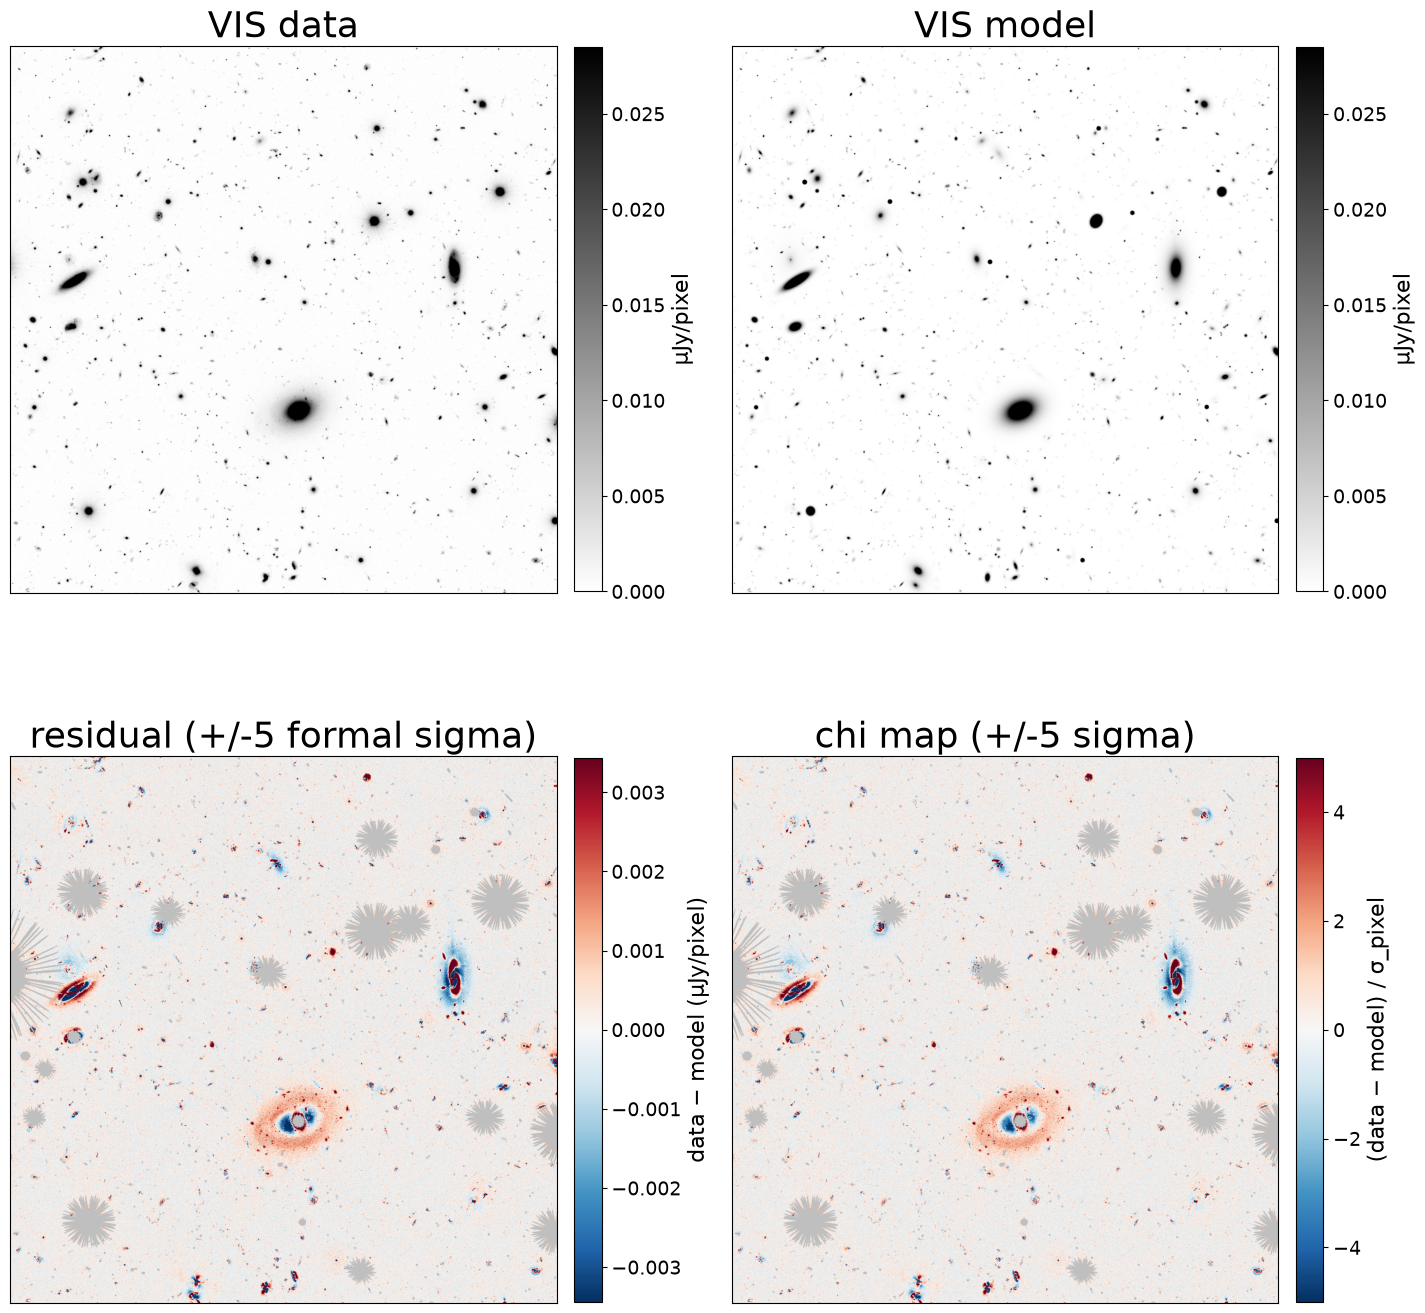

VIS formal per-pixel sigma:    0.0011951 counts
VIS empirical residual sigma:  0.00081835 counts
VIS chi std:                   1.110


In [14]:
res = ep.measure_residual(tractor_vis, tim_vis)
invvar_vis = tim_vis.getInvvar()

fig, axes = plt.subplots(2, 2, figsize=(14.5, 14.5))
UJY = ep.viz.ujy_per_unit(cutouts['VIS'])  # microJansky per image unit
vmax = float(np.nanpercentile(res['data'], 99.5)) * UJY
axes[0, 0].imshow(res['data'] * UJY,  origin='lower', cmap='gray_r', vmin=0, vmax=vmax)
axes[0, 0].set_title('VIS data')
axes[0, 1].imshow(res['model'] * UJY, origin='lower', cmap='gray_r', vmin=0, vmax=vmax)
axes[0, 1].set_title('VIS model')
for ax in axes[0]:
    ep.viz.add_colorbar(ax, label='µJy/pixel')
_, info_vis_res = ep.viz.show_residual(
    res['data'], res['model'], invvar=invvar_vis, scale=UJY, unit='µJy/pixel',
    ax=axes[1, 0], title='residual (+/-5 formal sigma)')
_, info_vis_chi = ep.viz.show_chi_map(
    res['data'], res['model'], invvar_vis,
    ax=axes[1, 1], title='chi map (+/-5 sigma)')
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
    ax.title.set_fontsize(26)
plt.tight_layout(); plt.show()

print(f"VIS formal per-pixel sigma:    {info_vis_res['formal_sigma']:.5g} counts")
print(f"VIS empirical residual sigma:  {info_vis_res['residual_std']:.5g} counts")
print(f"VIS chi std:                   {info_vis_chi['chi_std']:.3f}")

*VIS data and model (top); the residual in units of the median formal pixel error and the
residual divided by each pixel's own error (bottom). Masked pixels are gray.*

## 10. VIS: Tractor versus MER

Compare the fitted VIS flux with the MER measurement: `flux_vis_psf` for
sources MER classifies as stars and `flux_vis_sersic` for the rest. Our
own model classes come from the model selection chosen in `PRIOR`, so the
two need not agree. Sources the fit could not constrain are left out, and
sources near bright stars or the cutout edge are shown separately.


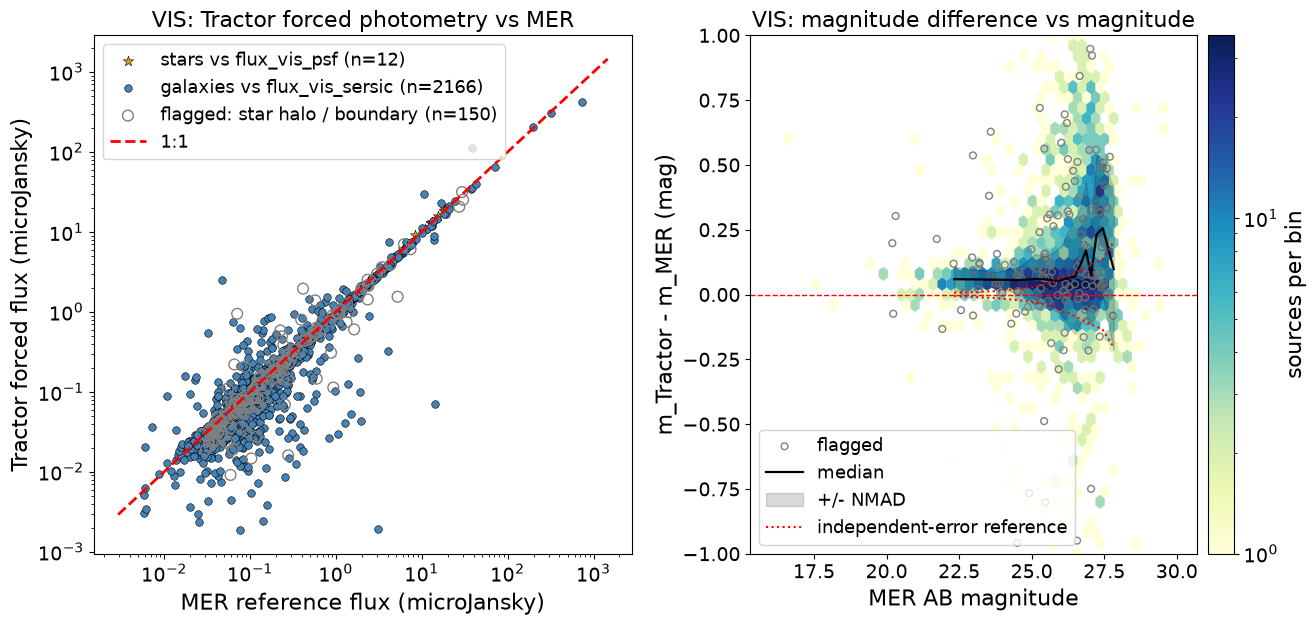

galaxies: median(Tractor / MER_sersic) = 0.937  (excluding flagged sources: 0.938, n=2166)
median and NMAD of m_Tractor - m_MER in equal-count magnitude bins:
  22.33 mag: median +0.059, NMAD 0.048
  23.75 mag: median +0.057, NMAD 0.029
  24.64 mag: median +0.056, NMAD 0.055
  25.10 mag: median +0.060, NMAD 0.096
  25.49 mag: median +0.059, NMAD 0.088
  25.78 mag: median +0.053, NMAD 0.114
  26.02 mag: median +0.056, NMAD 0.131
  26.28 mag: median +0.065, NMAD 0.187
  26.49 mag: median +0.068, NMAD 0.223
  26.69 mag: median +0.117, NMAD 0.225
  26.87 mag: median +0.170, NMAD 0.261
  27.04 mag: median +0.074, NMAD 0.189
  27.24 mag: median +0.232, NMAD 0.309
  27.45 mag: median +0.256, NMAD 0.265
  27.82 mag: median +0.098, NMAD 0.313


In [15]:
tractor_vis_ujy = np.array(
    [s.brightness.getFlux('VIS') for s in sources]) * 3.631
is_star = np.asarray(mer_cat['is_star'], dtype=bool)
ref_star = np.asarray(mer_cat['flux_vis_psf'],    dtype=float)
ref_gal  = np.asarray(mer_cat['flux_vis_sersic'], dtype=float)

# Bright-star halos and clipped boundary profiles bias both axes; flag them
# so the plot and the medians separate them.
flags9 = ep.flag_sources(
    [s.getPosition().ra for s in sources], [s.getPosition().dec for s in sources],
    ref_star, ep.probable_bright_stars(mer_cat),
    wcs=cutouts['VIS'].wcs, shape=cutouts['VIS'].shape,
    flag_plane=cutouts['VIS'].flag)
contam = ~np.asarray(flags9['reliable'])

# A nan error means a fully masked source frozen at its seed, not a measurement.
measured = np.isfinite(vis_err_ujy)
m_s = fit_quality & measured & is_star  & (ref_star > 0) & (tractor_vis_ujy > 0)
m_g = fit_quality & measured & ~is_star & (ref_gal  > 0) & (tractor_vis_ujy > 0)

fig, (ax, axd) = plt.subplots(1, 2, figsize=(13.5, 6.5))
ax.scatter(ref_star[m_s & ~contam], tractor_vis_ujy[m_s & ~contam],
           c='goldenrod', marker='*', s=60, edgecolors='k', linewidths=0.4,
           label=f'stars vs flux_vis_psf (n={int((m_s & ~contam).sum())})')
ax.scatter(ref_gal[m_g & ~contam], tractor_vis_ujy[m_g & ~contam],
           c='steelblue', s=30, edgecolors='k', linewidths=0.4,
           label=f'galaxies vs flux_vis_sersic (n={int((m_g & ~contam).sum())})')
_xc = np.where(is_star, ref_star, ref_gal)
_mc = (m_s | m_g) & contam
ax.scatter(_xc[_mc], tractor_vis_ujy[_mc], facecolors='none',
           edgecolors='0.5', s=60, linewidths=1.0,
           label=f'flagged: star halo / boundary (n={int(_mc.sum())})')
all_x = np.concatenate([ref_star[m_s], ref_gal[m_g]])
if len(all_x):
    ax.plot([all_x.min()*0.5, all_x.max()*2],
            [all_x.min()*0.5, all_x.max()*2],
            'r--', lw=2, label='1:1')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('MER reference flux (microJansky)')
ax.set_ylabel('Tractor forced flux (microJansky)')
ax.legend()
ax.set_title('VIS: Tractor forced photometry vs MER')

ref = np.where(is_star, ref_star, ref_gal)
sel = m_s | m_g
_em_psf = np.ma.filled(np.ma.asarray(mer_cat['fluxerr_vis_psf'], float), np.nan)
_em_ser = np.ma.filled(np.ma.asarray(mer_cat['fluxerr_vis_sersic'], float), np.nan)
err_mer = np.where(is_star, _em_psf, _em_ser)
_, dstat = ep.viz.show_dmag_vs_mag(
    ref, tractor_vis_ujy, err_ujy=vis_err_ujy, ref_err_ujy=err_mer,
    sel=sel & ~contam, flagged=sel & contam, ax=axd,
    xlabel='MER AB magnitude', ylabel='m_Tractor - m_MER (mag)',
    title='VIS: magnitude difference vs magnitude')
axd.legend(fontsize=13)
plt.tight_layout(); plt.show()

med_g = float(np.median(tractor_vis_ujy[m_g] / ref_gal[m_g]))
m_gc = m_g & ~contam
med_gc = float(np.median(tractor_vis_ujy[m_gc] / ref_gal[m_gc]))
print(f"galaxies: median(Tractor / MER_sersic) = {med_g:.3f}  "
      f"(excluding flagged sources: {med_gc:.3f}, n={int(m_gc.sum())})")
print("median and NMAD of m_Tractor - m_MER in equal-count magnitude bins:")
for c, m, s in zip(dstat['centers'], dstat['median'], dstat['nmad']):
    print(f"  {c:5.2f} mag: median {m:+.3f}, NMAD {s:.3f}")


*Left: the fitted VIS flux against the MER measurement. Right: the magnitude difference
against MER magnitude, with the median and NMAD scatter per bin. The dotted curve combines
the reported errors assuming independence; both measurements use the same images, so it is
only a reference scale.*

## 11. Inspect a source

Change `SOURCE_INDEX` and rerun the cell to view another source, without
refitting. Indices start at 0; try 166, 59 or 0 in this field.
The model includes neighbours. Gray residual pixels were excluded from fitting.


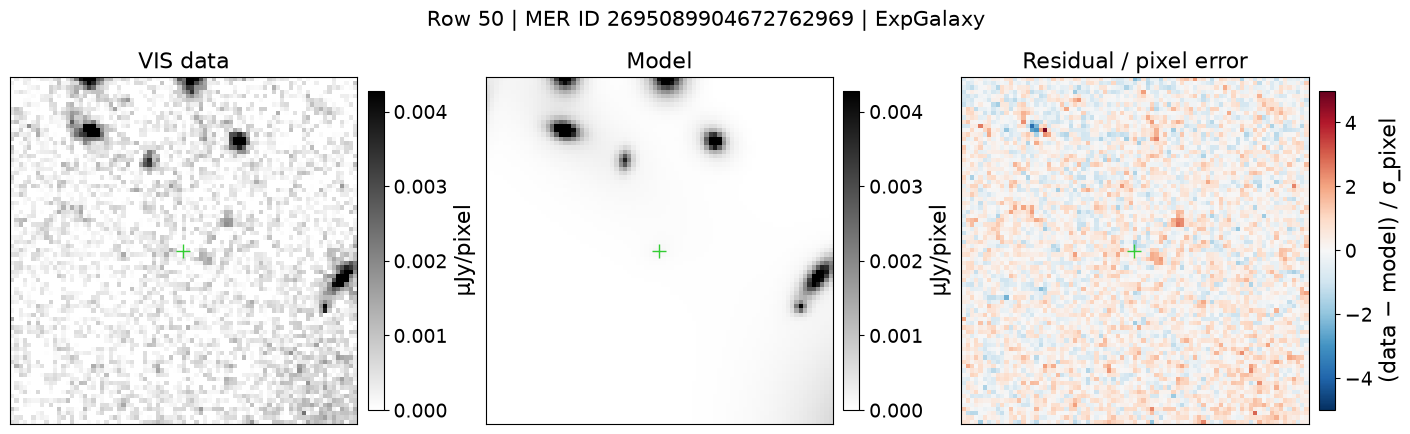

VIS flux guard passed: True; source flags: none
VIS fit: 0.004 +/- 0.006 microJansky (formal error)
MER Sérsic reference: 0.159 microJansky


In [16]:
SOURCE_INDEX = 50  # change this number and rerun this cell

if not isinstance(SOURCE_INDEX, (int, np.integer)) or not 0 <= SOURCE_INDEX < len(sources):
    raise ValueError(f"Choose an integer SOURCE_INDEX from 0 to {len(sources) - 1}.")
i = SOURCE_INDEX
quality = flags9

# Crop the existing data and full-scene model; no new fit is performed.
x, y = tim_vis.getWcs().positionToPixel(sources[i].getPosition())
xi, yi, half = int(round(x)), int(round(y)), 40
height, width = res['data'].shape
x0, x1 = max(0, xi - half), min(width, xi + half + 1)
y0, y1 = max(0, yi - half), min(height, yi + half + 1)
stamp = np.s_[y0:y1, x0:x1]
data, model, weight = res['data'][stamp], res['model'][stamp], tim_vis.getInvvar()[stamp]
UJY = ep.viz.ujy_per_unit(cutouts['VIS'])
vmax = max(float(np.nanpercentile(data, 99.5)), np.finfo(float).eps) * UJY

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
for ax, pixels, title in zip(axes[:2], (data, model), ('VIS data', 'Model')):
    ax.imshow(pixels * UJY, origin='lower', cmap='gray_r', vmin=0, vmax=vmax)
    ep.viz.add_colorbar(ax, label='µJy/pixel')
    ax.set_title(title)
ep.viz.show_chi_map(data, model, weight, ax=axes[2], title='Residual / pixel error')
for ax in axes:
    ax.plot(x - x0, y - y0, '+', color='limegreen', ms=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Row {i} | MER ID {int(mer_cat['object_id'][i])} | {type(sources[i]).__name__}", fontsize=15)
plt.show()

flags = [name for name in ('bright_star', 'near_bright_star', 'masked', 'edge') if quality[name][i]]
print(f"VIS flux guard passed: {bool(fit_quality[i])}; source flags: {', '.join(flags) or 'none'}")
if measured[i]:
    print(f"VIS fit: {tractor_vis_ujy[i]:.3f} +/- {vis_err_ujy[i]:.3f} microJansky (formal error)")
else:
    print("Flux unconstrained: the stored model amplitude is not a measurement.")
reference = ref_star[i] if is_star[i] else ref_gal[i]
print(f"MER {'PSF' if is_star[i] else 'Sérsic'} reference: {reference:.3f} microJansky")


*One source with its neighbours: the VIS data, the model, and the residual divided by the
pixel error. Gray residual pixels were excluded from the fit.*

## 12. Empirical calibration of the flux errors

Formal errors treat pixels as independent, while the delivered MER
mosaics contain correlated noise from resampling. We fit point-source
fluxes at empty positions and measure the scatter of flux/error, which
sets the error scale for point sources on this image.

VIS: 200 empty positions, flux/err scatter (chi_mad) = 1.051
     formal err median = 0.0026 uJy, empirical sigma = 0.0029 uJy
     adopted inflation = x1.051 (clamped at >= 1; errors are never deflated)


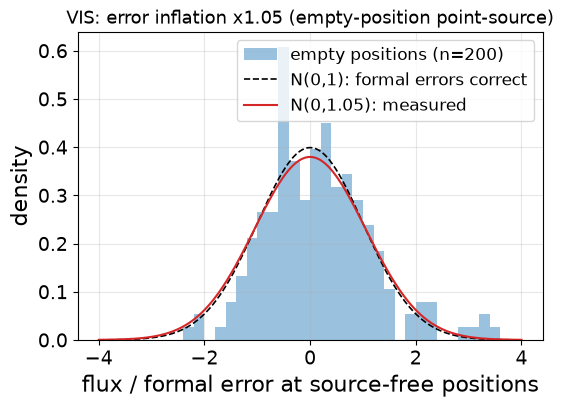

In [17]:
calib_vis = ep.measure_error_inflation(
    cutouts['VIS'], mer_cat=mer_cat, psf_data=psf_data_vis, band='VIS',
    n_positions=200, invvar=tim_vis.getInvvar(), rng=0)
print(f"VIS: {calib_vis['n_positions']} empty positions, "
      f"flux/err scatter (chi_mad) = {calib_vis['chi_mad']:.3f}")
print(f"     formal err median = {calib_vis['formal_err_med_ujy']:.4f} uJy, "
      f"empirical sigma = {calib_vis['empirical_sigma_ujy']:.4f} uJy")
print(f"     adopted inflation = x{calib_vis['inflation']:.3f} "
      f"(clamped at >= 1; errors are never deflated)")

ep.viz.show_error_calibration(calib_vis)
plt.show()

*Flux divided by its formal error at empty VIS positions. The width of the measured
distribution relative to the unit Gaussian is the error inflation factor.*

## 13. NISP PSFs

Use the same selected product for Y, J, and H. Each band supplies its own
stamps from the tile used for its science image; each source uses its
nearest sample in that band.


In [18]:
psf_data_nisp = {}
for band in ('Y', 'J', 'H'):
    psf_data_nisp[band] = extract_psf(
        band, TARGET_RA, TARGET_DEC, radius_arcsec=150.0,
        tile_id=cutouts[band].header.get('MERTILE'), force_download=True)
    fwhm = float(np.median(psf_data_nisp[band]['fwhm']))
    print(f"  NISP-{band} {PSF_PRODUCT.upper()}-PSF: {len(psf_data_nisp[band]['stamps'])} stamps, "
          f"median FWHM = {fwhm:.3f} arcsec")


  NISP-Y GRID-PSF: 493 stamps, median FWHM = 0.493 arcsec
  NISP-J GRID-PSF: 493 stamps, median FWHM = 0.519 arcsec
  NISP-H GRID-PSF: 493 stamps, median FWHM = 0.564 arcsec


## 14. Forced photometry in H, step by step

This is the forced fit of notebook 00 applied to every source at once. Each band runs the same
four steps, written out here for H:

1. **Tractor image.** `build_tractor_image` takes the H pixels, their inverse variance from the
   RMS plane with the band's own invalid and saturated pixels removed, the H PSF samples, and the
   MER zeropoint. The bright-star mask of section 5 is reused: all MER mosaics share one 0.1 arcsec
   grid, so a VIS pixel mask applies to H unchanged.
2. **Source models.** `clone_sources` copies the VIS models with their positions and shapes and
   gives each a new H flux. Each source is rendered with its nearest H PSF sample, so the same
   VIS shape becomes a wider H image.
3. **Solve.** `forced.flux_tractor` freezes everything but the fluxes, and `forced.solve_fluxes`
   solves for all of them together. With shapes fixed, the model is linear in the fluxes, so
   this is one linear least-squares problem; neighbours that overlap in H share their light
   according to their VIS shapes.
4. **Errors.** The inverse variance of each flux becomes a formal 1-sigma error; section 16 then
   scales it with the empty-position calibration of section 12.

In [19]:
from euclid_phot import forced
from euclid_phot.sources import clone_sources

band = "H"
# 1. The Tractor image
tim_h = ep.build_tractor_image(cutouts[band], psf_data=psf_data_nisp[band], pixel_mask=star_mask)
# 2. The VIS models in H: positions and shapes kept, a new flux
h_sources = clone_sources(sources, band)
# 3. Only the fluxes free; one linear solve for all sources together
tractor_h = forced.flux_tractor(tim_h, h_sources)
solved = forced.solve_fluxes(tractor_h)
# 4. Fluxes and formal 1-sigma errors in microJansky
step_flux = forced.fluxes_ujy(h_sources, band)
step_err = forced.flux_errors_ujy(forced.flux_inverse_variance(solved, tractor_h, len(h_sources)))
print(f"{len(h_sources)} sources; H S/N > 5 for {int(np.sum(step_flux / step_err > 5))}")

2365 sources; H S/N > 5 for 1426


### H data, model, and residual

The same layout as section 9. The model is the VIS source list rendered with the H PSF at the
fitted fluxes. As in notebook 00, the residual in H is smoother than in VIS: NISP's 0.3 arcsec
detector pixels are resampled onto the 0.1 arcsec grid, which correlates neighbouring pixels.

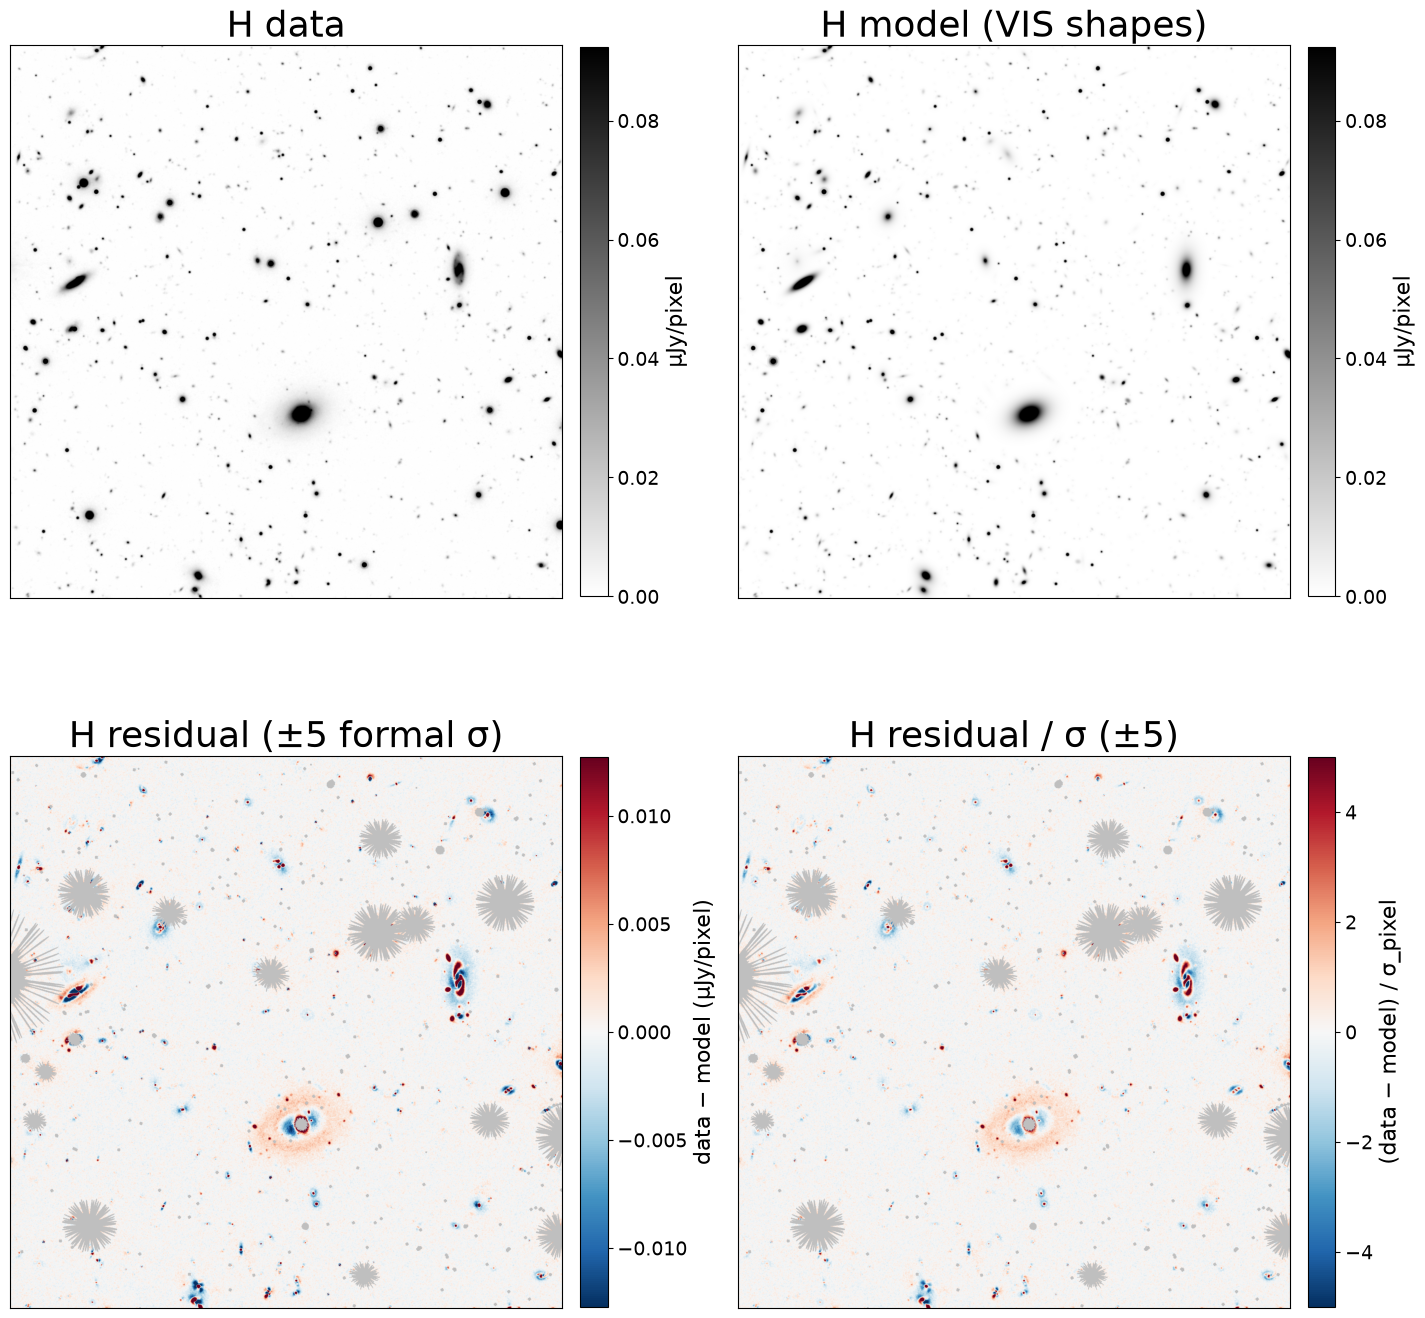

H formal per-pixel sigma:    0.70086 counts
H empirical residual sigma:  0.1835 counts
H chi std:                   0.507  (VIS: 1.110)


In [20]:
res_h = ep.measure_residual(tractor_h, tim_h)
invvar_h = tim_h.getInvvar()
UJY_H = ep.viz.ujy_per_unit(cutouts[band])
vmax_h = float(np.nanpercentile(res_h['data'], 99.5)) * UJY_H

fig, axes = plt.subplots(2, 2, figsize=(14.5, 14.5))
axes[0, 0].imshow(res_h['data'] * UJY_H, origin='lower', cmap='gray_r', vmin=0, vmax=vmax_h)
axes[0, 0].set_title(f'{band} data')
axes[0, 1].imshow(res_h['model'] * UJY_H, origin='lower', cmap='gray_r', vmin=0, vmax=vmax_h)
axes[0, 1].set_title(f'{band} model (VIS shapes)')
for ax in axes[0]:
    ep.viz.add_colorbar(ax, label='µJy/pixel')
_, info_h_res = ep.viz.show_residual(
    res_h['data'], res_h['model'], invvar=invvar_h, scale=UJY_H, unit='µJy/pixel',
    ax=axes[1, 0], title=f'{band} residual (±5 formal σ)')
_, info_h_chi = ep.viz.show_chi_map(
    res_h['data'], res_h['model'], invvar_h, ax=axes[1, 1], title=f'{band} residual / σ (±5)')
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
    ax.title.set_fontsize(26)
plt.tight_layout(); plt.show()

print(f"{band} formal per-pixel sigma:    {info_h_res['formal_sigma']:.5g} counts")
print(f"{band} empirical residual sigma:  {info_h_res['residual_std']:.5g} counts")
print(f"{band} chi std:                   {info_h_chi['chi_std']:.3f}  (VIS: {info_vis_chi['chi_std']:.3f})")

*H data and model (top); the residual in units of the median formal pixel error and the
residual divided by each pixel's own error (bottom). Masked pixels are gray.*

### Y, J, and H with `fit_nisp_forced`

`fit_nisp_forced` runs the same four steps for each band; its H fluxes are the ones above.
`result.image_set(band)` of section 16 returns the data, model, and residual images of any band
for the same kind of figure.

In [21]:
t0 = time.time()
nisp_results = ep.fit_nisp_forced(
    sources,
    {b: cutouts[b]        for b in ('Y', 'J', 'H')},
    pixel_mask=star_mask,
    n_workers=N_WORKERS, psf_data=psf_data_nisp,
)
nisp_flux_ujy = {b: nisp_results[b]['flux_ujy']     for b in ('Y', 'J', 'H')}
nisp_err_ujy  = {b: nisp_results[b]['flux_err_ujy'] for b in ('Y', 'J', 'H')}
print(f"NISP forced phot done in {time.time()-t0:.1f} s")
for band in ('Y', 'J', 'H'):
    f = nisp_flux_ujy[band]
    print(f"  {band}: flux range {np.nanmin(f):.2f} to {np.nanmax(f):.0f} microJansky")

NISP forced phot done in 57.6 s
  Y: flux range -0.58 to 728 microJansky
  J: flux range -0.46 to 837 microJansky
  H: flux range -0.73 to 963 microJansky


## 15. NISP versus MER

Compare against MER `flux_<band>_templfit`, measured with T-PHOT.
Its image templates and flux definition differ from our smooth VIS profiles,
so this is a cross-check rather than a calibration target. The panels show
flux ratios and magnitude differences for positive fitted fluxes with formal
S/N > 5; medians and NMAD summarize that selected sample.

MER template-fit colors use `FLUX_VIS_TO_<band>_TEMPLFIT` as their VIS
reference, so the flux ratios here are not directly color offsets. See the
[MER cookbook](https://euclid.esac.esa.int/dr/q1/dpdd/merdpd/merphotometrycookbook.html).

Y: n=1136, median(Tractor/MER_templfit) = 0.989, NMAD(dmag) = 0.115 mag
J: n=1337, median(Tractor/MER_templfit) = 0.993, NMAD(dmag) = 0.124 mag
H: n=1421, median(Tractor/MER_templfit) = 0.998, NMAD(dmag) = 0.124 mag


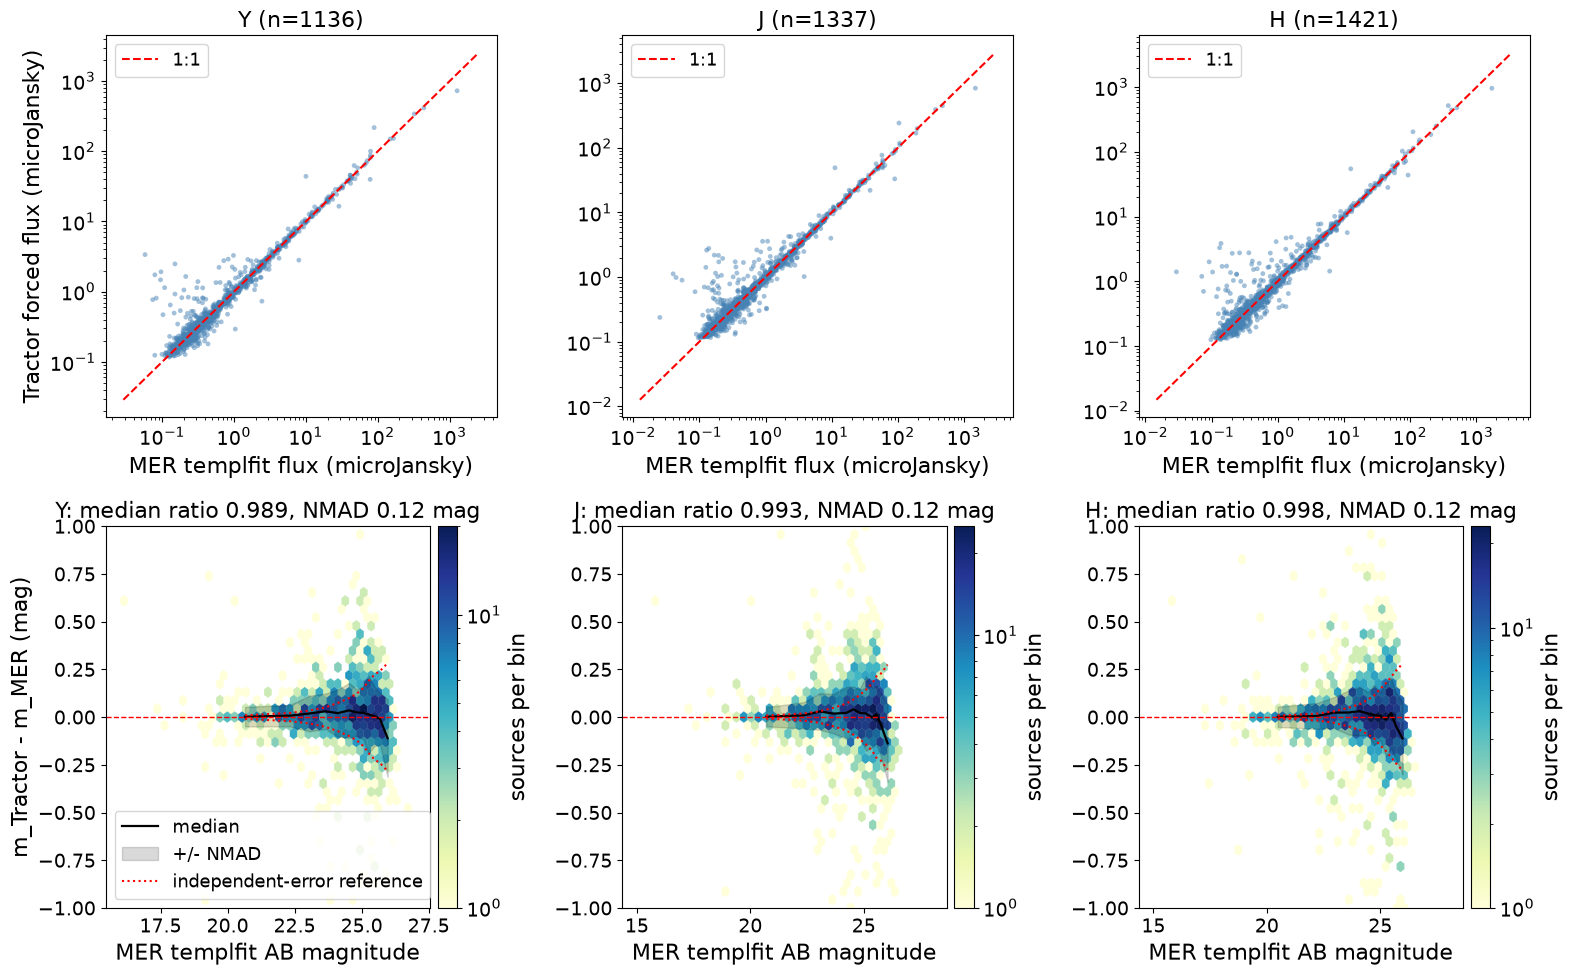

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for col, band in enumerate(('Y', 'J', 'H')):
    ours = np.asarray(nisp_flux_ujy[band], float)
    errs = np.asarray(nisp_err_ujy[band], float)
    ref_n = np.ma.filled(
        np.ma.asarray(mer_cat[f'flux_{band.lower()}_templfit'], float), np.nan)
    with np.errstate(invalid='ignore', divide='ignore'):
        snr = ours / errs
    ok = (fit_quality & np.isfinite(ours) & np.isfinite(ref_n)
          & (ref_n > 0) & (ours > 0) & (snr > 5))

    # Top: flux-flux relation against the 1:1 line.
    axf = axes[0, col]
    axf.scatter(ref_n[ok], ours[ok], s=12, c='steelblue', alpha=0.5,
                edgecolors='none')
    lims = (float(np.nanmin(ref_n[ok])) * 0.5,
            float(np.nanmax(ref_n[ok])) * 2.0)
    axf.plot(lims, lims, 'r--', lw=1.5, label='1:1')
    axf.set_xscale('log'); axf.set_yscale('log')
    axf.set_xlabel('MER templfit flux (microJansky)')
    axf.set_title(f'{band} (n={int(ok.sum())})')
    axf.legend(fontsize=13)

    # Bottom: magnitude difference vs magnitude through the same helper
    # as the VIS comparison in section 10.
    err_n = np.ma.filled(np.ma.asarray(
        mer_cat[f'fluxerr_{band.lower()}_templfit'], float), np.nan)
    med = float(np.median(ours[ok] / ref_n[ok]))
    nmad = float(mad_std(-2.5 * np.log10(ours[ok] / ref_n[ok])))
    ep.viz.show_dmag_vs_mag(
        ref_n, ours, err_ujy=errs, ref_err_ujy=err_n, sel=ok,
        ax=axes[1, col], gridsize=40, max_bins=12,
        xlabel='MER templfit AB magnitude',
        ylabel='m_Tractor - m_MER (mag)' if col == 0 else '',
        title=f'{band}: median ratio {med:.3f}, NMAD {nmad:.2f} mag')
    print(f"{band}: n={int(ok.sum())}, median(Tractor/MER_templfit) = "
          f"{med:.3f}, NMAD(dmag) = {nmad:.3f} mag")
axes[0, 0].set_ylabel('Tractor forced flux (microJansky)')
axes[1, 0].legend(fontsize=13, loc='lower left')
plt.tight_layout(); plt.show()


*Top: Tractor flux against the MER template-fit flux in each NISP band, for sources with
S/N above 5. Bottom: the magnitude difference against MER magnitude, with the median and
NMAD scatter per bin.*

## 16. The multi-band catalog

The result table has one row per source with the flux density in microJansky, its estimated
uncertainty, the AB magnitude, the model class, and quality flags, plus extinction-corrected
magnitudes and the calibration factors in its metadata. Non-positive fluxes have no AB
magnitude, and unconstrained measurements are NaN. The `reliable` flag records the bright-star
and edge checks of section 10. A row that failed the VIS flux guard is NaN in every band,
because the NISP fits need a VIS model; the catalog is in that sense VIS-selected.

The saved CSV keeps the rows with a measured VIS flux and the columns of
an ordinary photometry catalog: identifier, position, model class, the
`reliable` flag, and flux and magnitude with their errors per band.

In [23]:
from euclid_phot import ForcedPhotometryResult

fluxes = {'VIS': tractor_vis_ujy, **nisp_flux_ujy}
errors = {'VIS': vis_err_ujy, **nisp_err_ujy}
for band in fluxes:
    fluxes[band] = np.where(fit_quality, fluxes[band], np.nan)
    errors[band] = np.where(fit_quality, errors[band], np.nan)

result = ForcedPhotometryResult(
    target=(TARGET_RA, TARGET_DEC, CUTOUT_SIZE_ARCSEC),
    prior=dict(PRIOR), target_bands=dict(TARGET_BANDS),
    mer_cat=mer_cat, sources=sources,
    cutouts=cutouts,
    psf_data={"VIS": psf_data_vis, **psf_data_nisp},
    psf_mode="nearest-source-position",
    prior_pixel_mask=star_mask,
    fluxes_ujy=fluxes, flux_errs_ujy=errors,
    flux_quality=fit_quality,
    chosen_models=[type(s).__name__ for s in sources],
    data_dir=DATA_DIR,
)

# The section 12 calibration for every Euclid band; the factors go to the metadata.
ep.calibrate_result_errors(result, verbose=True)

catalog = result.to_table()
print(f"\n{len(catalog)} sources x {len(catalog.colnames)} columns")
print(f"error inflation: {catalog.meta['error_inflation']}")
print(f"5 x median-error equivalents (AB): {catalog.meta['depth_5sigma_ab']}")

keep = ['object_id', 'ra', 'dec', 'model', 'reliable'] + [
    c for c in catalog.colnames
    if c.startswith(('flux_', 'mag_')) and not c.endswith(('_extcorr', '_quality'))]
has_vis = np.isfinite(np.asarray(catalog['flux_VIS_ujy'], dtype=float))
catalog[keep][has_vis].write('DR1_forced_photometry_catalog.csv', overwrite=True)
print(f"wrote {int(has_vis.sum())} sources x {len(keep)} columns to {DATA_ACCESS}_forced_photometry_catalog.csv")

preview = catalog[np.isfinite(np.asarray(catalog['mag_VIS_ab']))].copy()
preview.sort('flux_VIS_ujy')
preview[['object_id', 'ra', 'dec', 'model', 'flux_VIS_ujy', 'mag_VIS_ab',
         'mag_Y_ab', 'mag_J_ab', 'mag_H_ab', 'reliable']][-8:].pprint_all()

  VIS: error inflation x1.05 (empty-position point-source, n=200)
  Y: error inflation x1.00 (empty-position point-source, n=200)
  J: error inflation x1.08 (empty-position point-source, n=200)
  H: error inflation x1.31 (empty-position point-source, n=199)

2365 sources x 41 columns
error inflation: {'VIS': 1.0509, 'Y': 1.0, 'J': 1.0755, 'H': 1.3055}
5 x median-error equivalents (AB): {'VIS': 27.764, 'Y': 25.86, 'J': 25.878, 'H': 25.559}
wrote 2338 sources x 21 columns to DR1_forced_photometry_catalog.csv
     object_id              ra               dec           model        flux_VIS_ujy        mag_VIS_ab          mag_Y_ab           mag_J_ab           mag_H_ab      reliable
                           deg               deg                            uJy                mag                mag                mag                mag                 
------------------- ----------------- ----------------- ------------ ------------------ ------------------ ------------------ ----------------